# Importamos librerías

In [1]:
import tensorflow as tf
import pathlib
import os
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import keras

In [2]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Flatten
from tensorflow.keras.layers import Dropout, BatchNormalization
from tensorflow.keras.initializers import HeNormal
from keras.regularizers import l1, l2

In [3]:
tf.test.is_gpu_available()

Instructions for updating:
Use `tf.config.list_physical_devices('GPU')` instead.


False

# Importamos los datos

In [4]:
path = '../../../data/noisy/Campo 100 puntos'

## Datos de entrenamiento

### Datos

In [5]:
campvectrain = np.load(path + '/campvectrain.npy')

In [6]:
np.shape(campvectrain)

(7000, 2, 100, 100)

### Coeficientes

In [7]:
coefcampvectrain = np.load(path + '/coefcampvectrain.npy')

In [8]:
np.shape(coefcampvectrain)

(7000, 7)

## Datos de prueba

### Datos

In [9]:
campvectest = np.load(path + '/campvectest.npy')

In [10]:
np.shape(campvectest)

(2000, 2, 100, 100)

### Coeficientes

In [11]:
coefcampvectest = np.load(path + '/coefcampvectest.npy')

In [12]:
np.shape(coefcampvectest)

(2000, 7)

## Datos de validación

### Datos

In [13]:
campvecval = np.load(path + '/campvecval.npy')

In [14]:
np.shape(campvecval)

(1000, 2, 100, 100)

### Coeficienes

In [15]:
coefcampvecval = np.load(path + '/coefcampvecval.npy')

In [16]:
np.shape(coefcampvecval)

(1000, 7)

# Unimos coeficientes con los datos

In [17]:
train_dataset = tf.data.Dataset.from_tensor_slices((campvectrain, coefcampvectrain))
test_dataset = tf.data.Dataset.from_tensor_slices((campvectest, coefcampvectest))
val_dataset = tf.data.Dataset.from_tensor_slices((campvecval, coefcampvecval))

In [18]:
train_dataset

<TensorSliceDataset element_spec=(TensorSpec(shape=(2, 100, 100), dtype=tf.float64, name=None), TensorSpec(shape=(7,), dtype=tf.int32, name=None))>

# Mezclar y procesar por lotes los conjuntos de datos

In [19]:
BATCH_SIZE = 100
SHUFFLE_BUFFER_SIZE = 100

train_dataset = train_dataset.shuffle(SHUFFLE_BUFFER_SIZE).batch(BATCH_SIZE)
test_dataset = test_dataset.batch(BATCH_SIZE)
val_dataset = val_dataset.batch(BATCH_SIZE)

# Creación del modelo

In [20]:
def custom_activation(x):
    return 10 * tf.nn.sigmoid(x)

In [21]:
model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(2,100,100)),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dense(100, activation='relu',kernel_initializer=HeNormal(), kernel_regularizer=l1(0.001)),
    tf.keras.layers.Dense(100, activation='relu',kernel_initializer=HeNormal(), kernel_regularizer=l1(0.001)),
    tf.keras.layers.Dense(50, activation='relu',kernel_initializer=HeNormal(), kernel_regularizer=l1(0.001)),
    tf.keras.layers.Dense(25, activation='relu',kernel_initializer=HeNormal(), kernel_regularizer=l1(0.001)),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dense(7, activation = custom_activation)
])

In [22]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization, Flatten
from tensorflow.keras.regularizers import l1

# Initialize the model
model = Sequential()

# Flatten for dense layers (assuming input shape is 2D)
model.add(Flatten(input_shape=(2, 100, 100)))

# First dense layer
model.add(BatchNormalization())  # Add BatchNormalization before dense layer
model.add(Dense(118, activation='sigmoid', kernel_initializer='glorot_uniform', kernel_regularizer=l1(0.001)))
model.add(Dropout(0.3177))  # Add dropout after dense layer

# Second dense layer
model.add(BatchNormalization())  # Add BatchNormalization before dense layer
model.add(Dense(114, activation='sigmoid', kernel_initializer='random_normal', kernel_regularizer=l1(0.001)))

model.add(Dense(7, activation=custom_activation))

# Display model architecture to verify
# model.summary()


In [23]:
model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 flatten_1 (Flatten)         (None, 20000)             0         
                                                                 
 batch_normalization_2 (Batc  (None, 20000)            80000     
 hNormalization)                                                 
                                                                 
 dense_5 (Dense)             (None, 118)               2360118   
                                                                 
 dropout_1 (Dropout)         (None, 118)               0         
                                                                 
 batch_normalization_3 (Batc  (None, 118)              472       
 hNormalization)                                                 
                                                                 
 dense_6 (Dense)             (None, 114)              

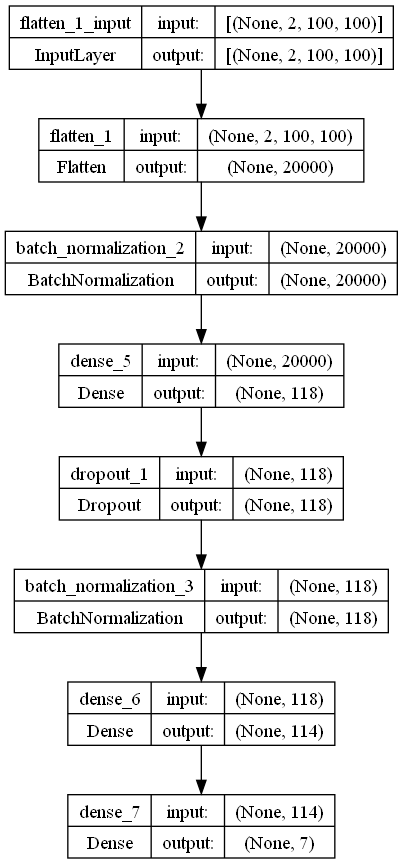

In [24]:
keras.utils.plot_model(model,show_shapes=True)

# Entrenamos el modelo

In [25]:
from keras.optimizers import Adam
optimizer = Adam(learning_rate=0.001,clipvalue=100.0)

In [26]:
def total_mae_loss(y_true, y_pred):
    total_loss = 0
    num_parameters = 7
    for i in range(num_parameters):
        total_loss += tf.keras.losses.mean_absolute_error(y_true[:, i], y_pred[:, i])
    tf.print(y_true, summarize = -1)
    tf.print(y_pred, summarize = -1)
    return total_loss / num_parameters

In [27]:
coeficientesnombres = ('a_1', 'a_2', 'b_1', 'b_2', 'd_1', 'd_2', 'n')

def mse_component(i):
    def mse_i(y_true, y_pred):
        return tf.keras.losses.mean_absolute_error(y_true[:, i], y_pred[:, i])

    mse_i.__name__ = coeficientesnombres[i]
    return mse_i

def mean_metric(y_true, y_pred):
    total_loss = 0
    for i in range(7):
        total_loss += mse_component(i)(y_true, y_pred)
    sum_of_true_coefficients = tf.reduce_sum(y_true, axis=-1)
    return total_loss / sum_of_true_coefficients

metrics = [mse_component(i) for i in range(7)] + [mean_metric]

In [29]:
model.compile(optimizer=optimizer,
              loss= 'mean_squared_error',
              metrics=metrics)

In [30]:
def scheduler(epoch, lr):
  if epoch < 400:
    return lr
  else:
    return -1.65e-6*epoch +  0.00166

def adaptive_learning_rate(epoch):
    initial_lr = 0.001
    final_lr = 0.00001  # Updated final learning rate
    start_decay_epoch = 100
    end_decay_epoch = 1000
    
    if epoch < start_decay_epoch:
        return initial_lr
    elif epoch >= start_decay_epoch and epoch <= end_decay_epoch:
        lr_range = initial_lr - final_lr
        decay_epochs = end_decay_epoch - start_decay_epoch
        decay_per_epoch = lr_range / decay_epochs
        return initial_lr - (epoch - start_decay_epoch) * decay_per_epoch
    else:
        return final_lr0166

In [31]:
val_epochs = 1000

early_stop = tf.keras.callbacks.EarlyStopping( monitor = 'val_mean_metric', patience = 100,verbose = 1, 
                                              restore_best_weights = True)

reduce_lr = tf.keras.callbacks.LearningRateScheduler(adaptive_learning_rate)
history = model.fit(train_dataset, validation_data=val_dataset, epochs= val_epochs, callbacks=[reduce_lr, early_stop])

Epoch 1/1000
70/70 [==============================] - 3s 26ms/step - loss: 12.5278 - a_1: 2.3640 - a_2: 2.3383 - b_1: 1.9296 - b_2: 1.9567 - d_1: 1.4315 - d_2: 1.4431 - n: 1.2561 - mean_metric: 0.3953 - val_loss: 7.2985 - val_a_1: 2.3577 - val_a_2: 2.3036 - val_b_1: 1.9402 - val_b_2: 2.0102 - val_d_1: 1.4616 - val_d_2: 1.4501 - val_n: 1.1716 - val_mean_metric: 0.4004 - lr: 0.0010
Epoch 2/1000
70/70 [==============================] - 2s 23ms/step - loss: 6.2012 - a_1: 1.9828 - a_2: 1.9544 - b_1: 1.5693 - b_2: 1.5388 - d_1: 1.2505 - d_2: 1.2579 - n: 1.2198 - mean_metric: 0.3349 - val_loss: 6.2234 - val_a_1: 2.0409 - val_a_2: 2.0298 - val_b_1: 1.6287 - val_b_2: 1.7396 - val_d_1: 1.1871 - val_d_2: 1.1867 - val_n: 1.1641 - val_mean_metric: 0.3462 - lr: 0.0010
Epoch 3/1000
70/70 [==============================] - 2s 23ms/step - loss: 6.0052 - a_1: 1.8572 - a_2: 1.8325 - b_1: 1.5081 - b_2: 1.4880 - d_1: 1.2348 - d_2: 1.2383 - n: 1.2203 - mean_metric: 0.3226 - val_loss: 5.7743 - val_a_1: 1.892

70/70 [==============================] - 2s 22ms/step - loss: 2.6987 - a_1: 1.1874 - a_2: 1.1859 - b_1: 1.0408 - b_2: 1.0236 - d_1: 0.9132 - d_2: 0.9220 - n: 0.8336 - mean_metric: 0.2209 - val_loss: 2.3988 - val_a_1: 1.1823 - val_a_2: 1.0232 - val_b_1: 0.9771 - val_b_2: 0.8916 - val_d_1: 0.8007 - val_d_2: 0.8042 - val_n: 0.6956 - val_mean_metric: 0.2013 - lr: 0.0010
Epoch 44/1000
70/70 [==============================] - 2s 22ms/step - loss: 2.6646 - a_1: 1.1619 - a_2: 1.1934 - b_1: 1.0184 - b_2: 1.0139 - d_1: 0.9029 - d_2: 0.9290 - n: 0.8202 - mean_metric: 0.2189 - val_loss: 2.4107 - val_a_1: 1.0485 - val_a_2: 1.0940 - val_b_1: 0.9933 - val_b_2: 0.8855 - val_d_1: 0.7916 - val_d_2: 0.8293 - val_n: 0.6997 - val_mean_metric: 0.2002 - lr: 0.0010
Epoch 45/1000
70/70 [==============================] - 2s 23ms/step - loss: 2.6913 - a_1: 1.1784 - a_2: 1.1921 - b_1: 1.0205 - b_2: 1.0326 - d_1: 0.9132 - d_2: 0.9265 - n: 0.8300 - mean_metric: 0.2205 - val_loss: 2.3819 - val_a_1: 1.0790 - val_a_2:

70/70 [==============================] - 2s 22ms/step - loss: 2.4802 - a_1: 1.1317 - a_2: 1.1309 - b_1: 0.9721 - b_2: 0.9611 - d_1: 0.8703 - d_2: 0.8834 - n: 0.7547 - mean_metric: 0.2085 - val_loss: 2.1360 - val_a_1: 1.0418 - val_a_2: 0.9676 - val_b_1: 0.9038 - val_b_2: 0.8032 - val_d_1: 0.7331 - val_d_2: 0.7505 - val_n: 0.5937 - val_mean_metric: 0.1829 - lr: 0.0010
Epoch 86/1000
70/70 [==============================] - 2s 22ms/step - loss: 2.4806 - a_1: 1.1278 - a_2: 1.1352 - b_1: 0.9759 - b_2: 0.9613 - d_1: 0.8723 - d_2: 0.8779 - n: 0.7530 - mean_metric: 0.2084 - val_loss: 2.1410 - val_a_1: 1.0325 - val_a_2: 0.9791 - val_b_1: 0.8566 - val_b_2: 0.8456 - val_d_1: 0.7488 - val_d_2: 0.7577 - val_n: 0.6111 - val_mean_metric: 0.1841 - lr: 0.0010
Epoch 87/1000
70/70 [==============================] - 2s 23ms/step - loss: 2.4544 - a_1: 1.1179 - a_2: 1.1335 - b_1: 0.9690 - b_2: 0.9547 - d_1: 0.8535 - d_2: 0.8645 - n: 0.7540 - mean_metric: 0.2067 - val_loss: 2.1281 - val_a_1: 1.0070 - val_a_2:

70/70 [==============================] - 2s 22ms/step - loss: 2.3505 - a_1: 1.1170 - a_2: 1.1010 - b_1: 0.9468 - b_2: 0.9449 - d_1: 0.8465 - d_2: 0.8665 - n: 0.7122 - mean_metric: 0.2032 - val_loss: 1.9745 - val_a_1: 0.9548 - val_a_2: 0.9583 - val_b_1: 0.8315 - val_b_2: 0.7696 - val_d_1: 0.7155 - val_d_2: 0.7182 - val_n: 0.5674 - val_mean_metric: 0.1742 - lr: 9.7140e-04
Epoch 128/1000
70/70 [==============================] - 2s 23ms/step - loss: 2.3533 - a_1: 1.1034 - a_2: 1.1088 - b_1: 0.9540 - b_2: 0.9469 - d_1: 0.8389 - d_2: 0.8761 - n: 0.7294 - mean_metric: 0.2039 - val_loss: 1.9971 - val_a_1: 0.9613 - val_a_2: 0.9710 - val_b_1: 0.8400 - val_b_2: 0.7687 - val_d_1: 0.7130 - val_d_2: 0.7441 - val_n: 0.5887 - val_mean_metric: 0.1764 - lr: 9.7030e-04
Epoch 129/1000
70/70 [==============================] - 2s 22ms/step - loss: 2.3312 - a_1: 1.1081 - a_2: 1.1168 - b_1: 0.9331 - b_2: 0.9347 - d_1: 0.8392 - d_2: 0.8654 - n: 0.7130 - mean_metric: 0.2025 - val_loss: 2.0219 - val_a_1: 0.9977 

70/70 [==============================] - 2s 22ms/step - loss: 2.2701 - a_1: 1.0951 - a_2: 1.0971 - b_1: 0.9492 - b_2: 0.9105 - d_1: 0.8319 - d_2: 0.8485 - n: 0.7019 - mean_metric: 0.2000 - val_loss: 1.9379 - val_a_1: 0.9646 - val_a_2: 0.9444 - val_b_1: 0.8770 - val_b_2: 0.7827 - val_d_1: 0.6972 - val_d_2: 0.7385 - val_n: 0.5704 - val_mean_metric: 0.1760 - lr: 9.2520e-04
Epoch 170/1000
70/70 [==============================] - 2s 23ms/step - loss: 2.2625 - a_1: 1.0884 - a_2: 1.0875 - b_1: 0.9544 - b_2: 0.9252 - d_1: 0.8315 - d_2: 0.8432 - n: 0.6933 - mean_metric: 0.1997 - val_loss: 1.9201 - val_a_1: 0.9147 - val_a_2: 0.9449 - val_b_1: 0.8240 - val_b_2: 0.7779 - val_d_1: 0.7037 - val_d_2: 0.7157 - val_n: 0.5717 - val_mean_metric: 0.1722 - lr: 9.2410e-04
Epoch 171/1000
70/70 [==============================] - 2s 22ms/step - loss: 2.2462 - a_1: 1.0731 - a_2: 1.0868 - b_1: 0.9322 - b_2: 0.9311 - d_1: 0.8233 - d_2: 0.8512 - n: 0.7017 - mean_metric: 0.1990 - val_loss: 1.9513 - val_a_1: 0.9555 

70/70 [==============================] - 2s 22ms/step - loss: 2.1743 - a_1: 1.0771 - a_2: 1.0875 - b_1: 0.9225 - b_2: 0.9107 - d_1: 0.8275 - d_2: 0.8311 - n: 0.6964 - mean_metric: 0.1975 - val_loss: 1.8853 - val_a_1: 0.9313 - val_a_2: 0.9275 - val_b_1: 0.8421 - val_b_2: 0.7972 - val_d_1: 0.7212 - val_d_2: 0.7099 - val_n: 0.5733 - val_mean_metric: 0.1738 - lr: 8.7900e-04
Epoch 212/1000
70/70 [==============================] - 2s 22ms/step - loss: 2.1828 - a_1: 1.0556 - a_2: 1.0718 - b_1: 0.9375 - b_2: 0.9246 - d_1: 0.8248 - d_2: 0.8182 - n: 0.7006 - mean_metric: 0.1969 - val_loss: 1.8819 - val_a_1: 0.9400 - val_a_2: 0.9482 - val_b_1: 0.8371 - val_b_2: 0.7615 - val_d_1: 0.7075 - val_d_2: 0.7140 - val_n: 0.5684 - val_mean_metric: 0.1730 - lr: 8.7790e-04
Epoch 213/1000
70/70 [==============================] - 2s 22ms/step - loss: 2.1602 - a_1: 1.0621 - a_2: 1.0523 - b_1: 0.9379 - b_2: 0.9139 - d_1: 0.8135 - d_2: 0.8325 - n: 0.6948 - mean_metric: 0.1961 - val_loss: 1.9061 - val_a_1: 0.9574 

... (14 outputs left out)

70/70 [==============================] - 2s 23ms/step - loss: 1.6132 - a_1: 1.0039 - a_2: 1.0011 - b_1: 0.8582 - b_2: 0.8468 - d_1: 0.7395 - d_2: 0.7475 - n: 0.6638 - mean_metric: 0.1822 - val_loss: 1.4110 - val_a_1: 0.8669 - val_a_2: 0.9004 - val_b_1: 0.7756 - val_b_2: 0.7312 - val_d_1: 0.6478 - val_d_2: 0.6727 - val_n: 0.5468 - val_mean_metric: 0.1624 - lr: 1.8600e-04
Epoch 842/1000
70/70 [==============================] - 2s 23ms/step - loss: 1.6243 - a_1: 1.0153 - a_2: 0.9958 - b_1: 0.8716 - b_2: 0.8564 - d_1: 0.7374 - d_2: 0.7546 - n: 0.6747 - mean_metric: 0.1836 - val_loss: 1.4074 - val_a_1: 0.8572 - val_a_2: 0.8948 - val_b_1: 0.7825 - val_b_2: 0.7271 - val_d_1: 0.6479 - val_d_2: 0.6672 - val_n: 0.5577 - val_mean_metric: 0.1622 - lr: 1.8490e-04
Epoch 843/1000
70/70 [==============================] - 2s 23ms/step - loss: 1.6028 - a_1: 1.0017 - a_2: 0.9821 - b_1: 0.8526 - b_2: 0.8564 - d_1: 0.7434 - d_2: 0.7590 - n: 0.6627 - mean_metric: 0.1822 - val_loss: 1.4173 - val_a_1: 0.8793 

70/70 [==============================] - 2s 22ms/step - loss: 1.5689 - a_1: 0.9914 - a_2: 0.9785 - b_1: 0.8637 - b_2: 0.8520 - d_1: 0.7454 - d_2: 0.7478 - n: 0.6561 - mean_metric: 0.1814 - val_loss: 1.3782 - val_a_1: 0.8622 - val_a_2: 0.9007 - val_b_1: 0.7712 - val_b_2: 0.7220 - val_d_1: 0.6356 - val_d_2: 0.6645 - val_n: 0.5470 - val_mean_metric: 0.1612 - lr: 1.3980e-04
Epoch 884/1000
70/70 [==============================] - 2s 22ms/step - loss: 1.5749 - a_1: 0.9855 - a_2: 0.9872 - b_1: 0.8703 - b_2: 0.8513 - d_1: 0.7354 - d_2: 0.7492 - n: 0.6688 - mean_metric: 0.1818 - val_loss: 1.3759 - val_a_1: 0.8547 - val_a_2: 0.8905 - val_b_1: 0.7730 - val_b_2: 0.7175 - val_d_1: 0.6367 - val_d_2: 0.6622 - val_n: 0.5508 - val_mean_metric: 0.1607 - lr: 1.3870e-04
Epoch 885/1000
70/70 [==============================] - 2s 22ms/step - loss: 1.5844 - a_1: 1.0008 - a_2: 0.9834 - b_1: 0.8623 - b_2: 0.8601 - d_1: 0.7420 - d_2: 0.7506 - n: 0.6653 - mean_metric: 0.1823 - val_loss: 1.3717 - val_a_1: 0.8609 

70/70 [==============================] - 2s 22ms/step - loss: 1.5539 - a_1: 0.9966 - a_2: 0.9882 - b_1: 0.8554 - b_2: 0.8397 - d_1: 0.7450 - d_2: 0.7521 - n: 0.6624 - mean_metric: 0.1815 - val_loss: 1.3568 - val_a_1: 0.8640 - val_a_2: 0.8872 - val_b_1: 0.7754 - val_b_2: 0.7219 - val_d_1: 0.6371 - val_d_2: 0.6609 - val_n: 0.5465 - val_mean_metric: 0.1609 - lr: 9.3600e-05
Epoch 926/1000
70/70 [==============================] - 2s 22ms/step - loss: 1.5335 - a_1: 0.9871 - a_2: 0.9705 - b_1: 0.8499 - b_2: 0.8522 - d_1: 0.7398 - d_2: 0.7430 - n: 0.6583 - mean_metric: 0.1803 - val_loss: 1.3542 - val_a_1: 0.8542 - val_a_2: 0.8968 - val_b_1: 0.7702 - val_b_2: 0.7203 - val_d_1: 0.6389 - val_d_2: 0.6641 - val_n: 0.5479 - val_mean_metric: 0.1609 - lr: 9.2500e-05
Epoch 927/1000
70/70 [==============================] - 2s 22ms/step - loss: 1.5436 - a_1: 0.9923 - a_2: 0.9802 - b_1: 0.8534 - b_2: 0.8430 - d_1: 0.7396 - d_2: 0.7506 - n: 0.6699 - mean_metric: 0.1812 - val_loss: 1.3541 - val_a_1: 0.8583 

70/70 [==============================] - 2s 22ms/step - loss: 1.5161 - a_1: 0.9948 - a_2: 0.9679 - b_1: 0.8512 - b_2: 0.8490 - d_1: 0.7438 - d_2: 0.7446 - n: 0.6583 - mean_metric: 0.1806 - val_loss: 1.3260 - val_a_1: 0.8574 - val_a_2: 0.8828 - val_b_1: 0.7634 - val_b_2: 0.7217 - val_d_1: 0.6364 - val_d_2: 0.6605 - val_n: 0.5503 - val_mean_metric: 0.1603 - lr: 4.7400e-05
Epoch 968/1000
70/70 [==============================] - 2s 22ms/step - loss: 1.5204 - a_1: 0.9830 - a_2: 0.9851 - b_1: 0.8609 - b_2: 0.8527 - d_1: 0.7348 - d_2: 0.7468 - n: 0.6591 - mean_metric: 0.1811 - val_loss: 1.3278 - val_a_1: 0.8609 - val_a_2: 0.8782 - val_b_1: 0.7633 - val_b_2: 0.7222 - val_d_1: 0.6386 - val_d_2: 0.6604 - val_n: 0.5491 - val_mean_metric: 0.1603 - lr: 4.6300e-05
Epoch 969/1000
70/70 [==============================] - 2s 22ms/step - loss: 1.5048 - a_1: 0.9943 - a_2: 0.9700 - b_1: 0.8423 - b_2: 0.8424 - d_1: 0.7322 - d_2: 0.7430 - n: 0.6600 - mean_metric: 0.1798 - val_loss: 1.3246 - val_a_1: 0.8554 

# Analizamos accuracy y loss

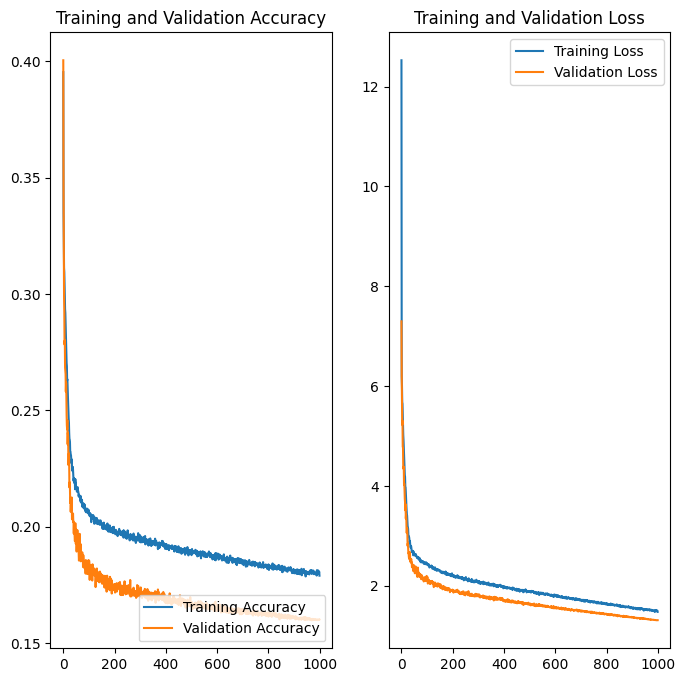

In [32]:
acc = history.history['mean_metric']
val_acc = history.history['val_mean_metric']

loss = history.history['loss']
val_loss = history.history['val_loss']

#epochs_range = range(val_epochs)
epochs_range = range(val_epochs)
plt.figure(figsize=(8, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

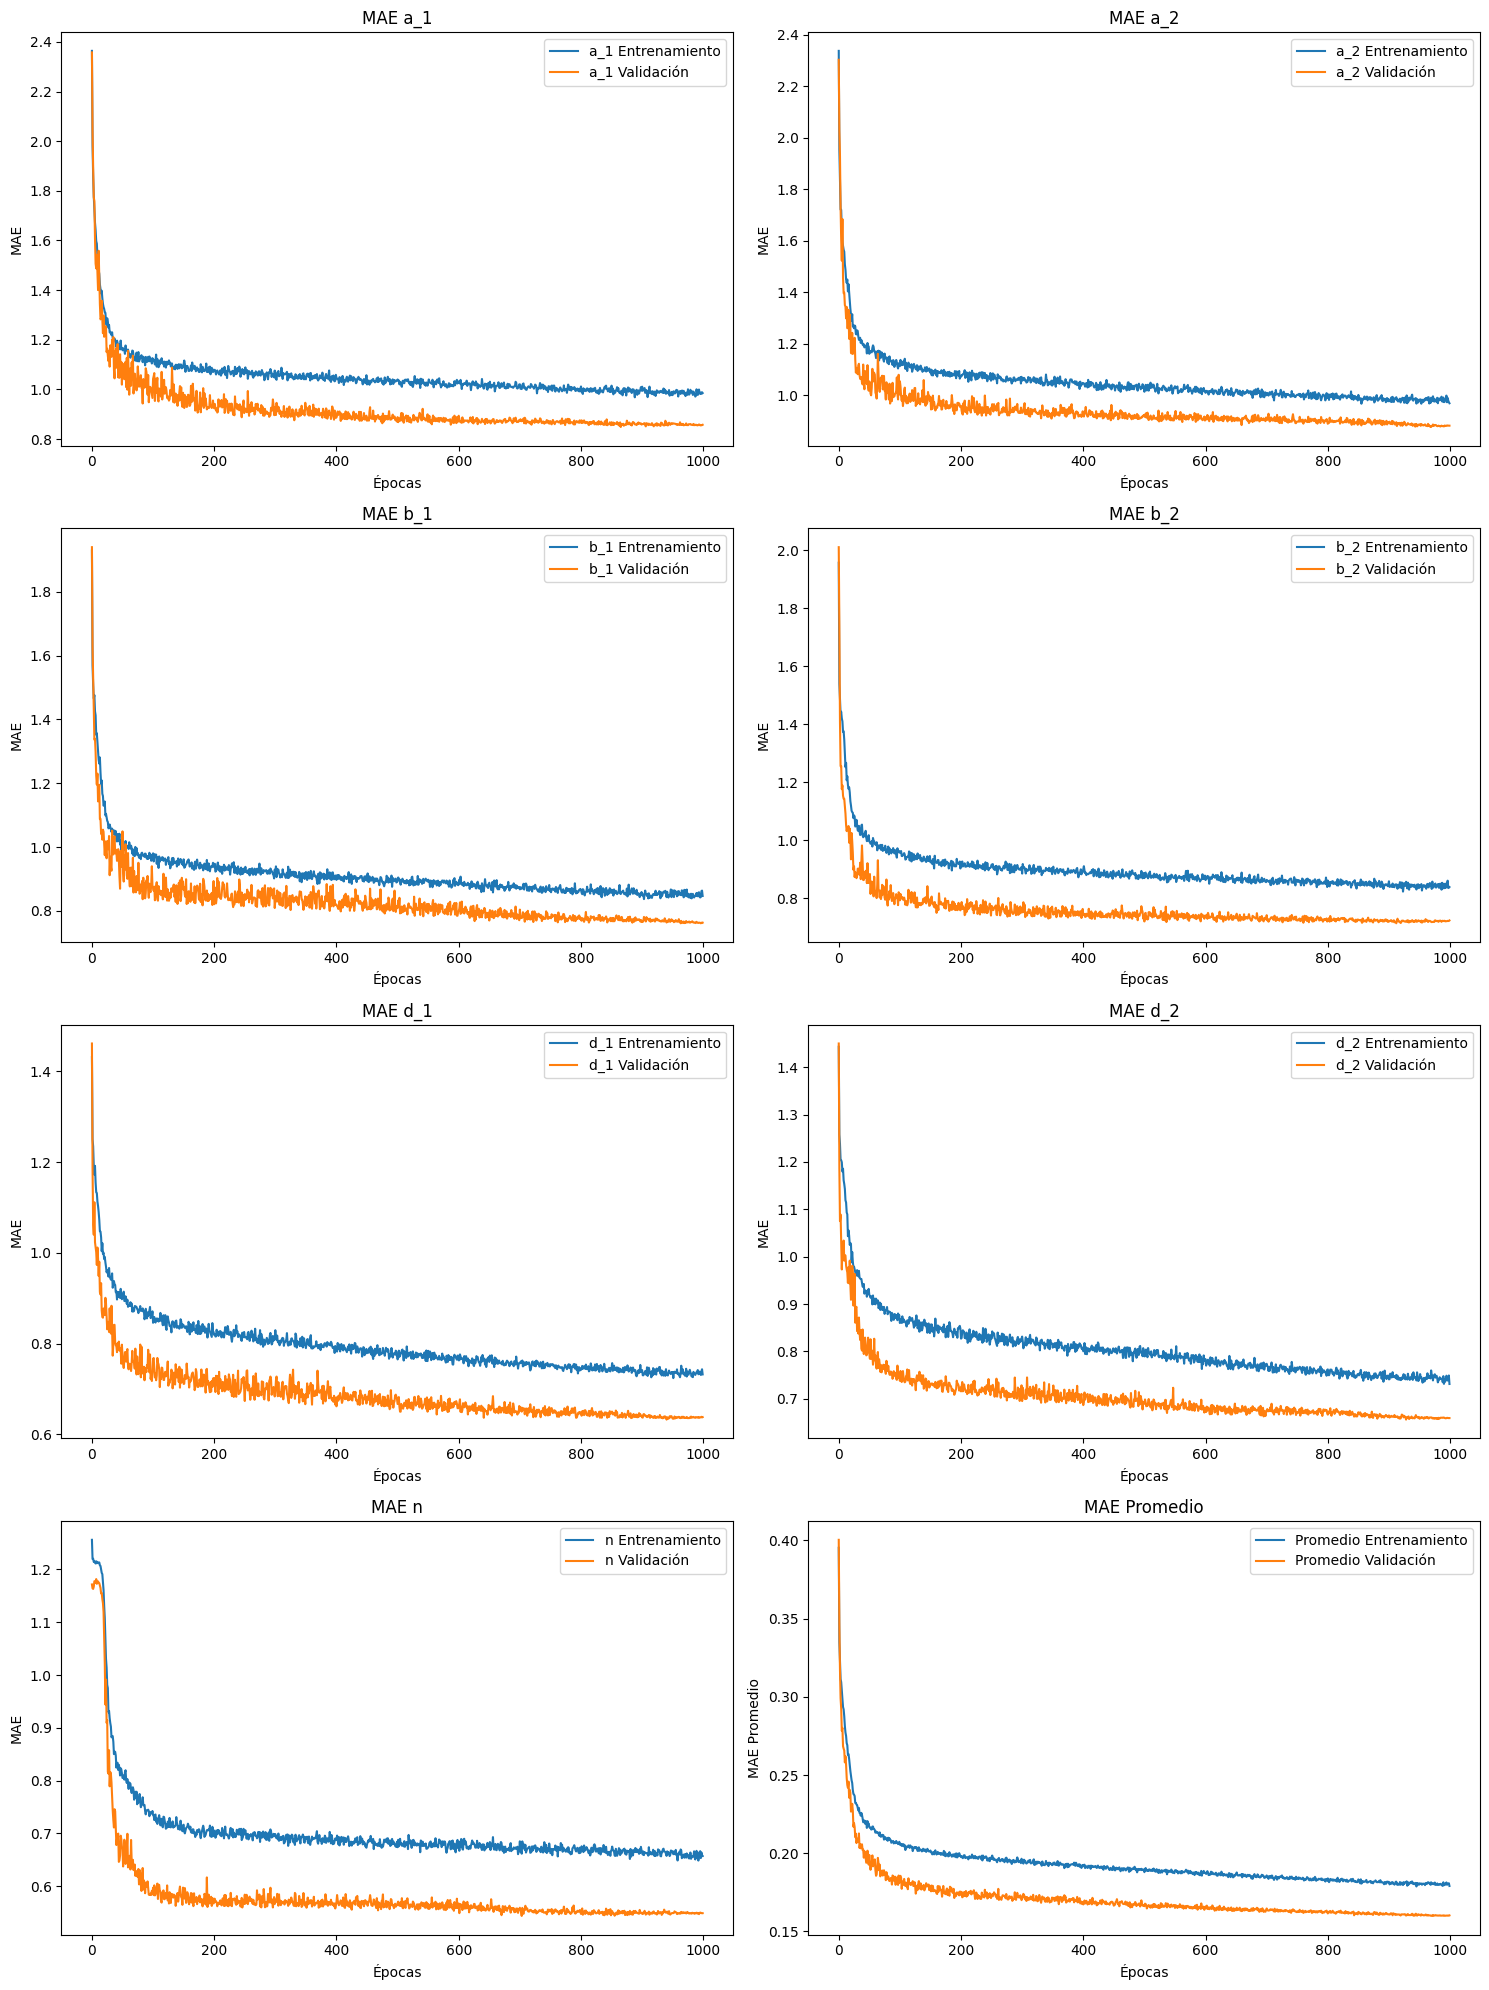

In [33]:
# Número de coeficientes más uno para la métrica adicional
n_coef = len(coeficientesnombres) + 1

# Número de filas y columnas para los subplots
n_rows = (n_coef + 1) // 2
n_cols = 2

# Crear una figura más grande para acomodar todos los subplots
plt.figure(figsize=(15, 5 * n_rows))

# Crear un subplot para cada coeficiente
for i, name in enumerate(coeficientesnombres):
    plt.subplot(n_rows, n_cols, i + 1)
    plt.plot(history.history[name ], label=name + ' Entrenamiento')
    plt.plot(history.history['val_' + name ], label=name + ' Validación')
    plt.title('MAE ' + name)
    plt.xlabel('Épocas')
    plt.ylabel('MAE')
    plt.legend()

# Agregar un subplot para la métrica prom_per
plt.subplot(n_rows, n_cols, n_coef)
plt.plot(history.history['mean_metric'], label='Promedio Entrenamiento')
plt.plot(history.history['val_mean_metric'], label='Promedio Validación')
plt.title('MAE Promedio')
plt.xlabel('Épocas')
plt.ylabel('MAE Promedio')
plt.legend()

# Ajustar el diseño para asegurarse de que todo encaje bien
plt.tight_layout()
plt.show()

# Evaluamos el modelo

In [34]:
test_loss, test_a1, test_a2, test_b1, test_b2, test_d1, test_d2, test_n, testprom_per = model.evaluate(
    campvectest, coefcampvectest)

63/63 [==============================] - 0s 3ms/step - loss: 1.2597 - a_1: 0.8376 - a_2: 0.8410 - b_1: 0.7387 - b_2: 0.7408 - d_1: 0.6601 - d_2: 0.6539 - n: 0.5670 - mean_metric: 0.1557


In [35]:
predictions = model.predict(campvectest)

63/63 [==============================] - 0s 2ms/step


In [36]:
print(coefcampvectest[0,:])
print(predictions[0,:])
from sklearn.metrics import mean_absolute_error
print(np.sum(coefcampvectest, axis=-1))

mae1 = mean_absolute_error(coefcampvectest[0,:], predictions[0,:])
mae1

[ 4  5  0  1  7 10  3]
[2.6557307  3.6586208  0.82856643 0.8442029  6.907246   8.792428
 3.5154138 ]
[30 33 23 ... 21 35 40]


0.7836788041251046

In [37]:
from sklearn.metrics import mean_absolute_error
import numpy as np

# Calcula el MAE
mae = mean_absolute_error(coefcampvectest, predictions)

# Calcula la desviación estándar del error
error = coefcampvectest - predictions
std_dev = np.std(error)

# Calcula el error absoluto máximo
max_error = np.max(np.abs(error))

print(f"MAE: {mae}, Desviación estándar del error: {std_dev}, Error absoluto máximo: {max_error}")

MAE: 0.7194443033340254, Desviación estándar del error: 0.9731045885275879, Error absoluto máximo: 5.50929069519043


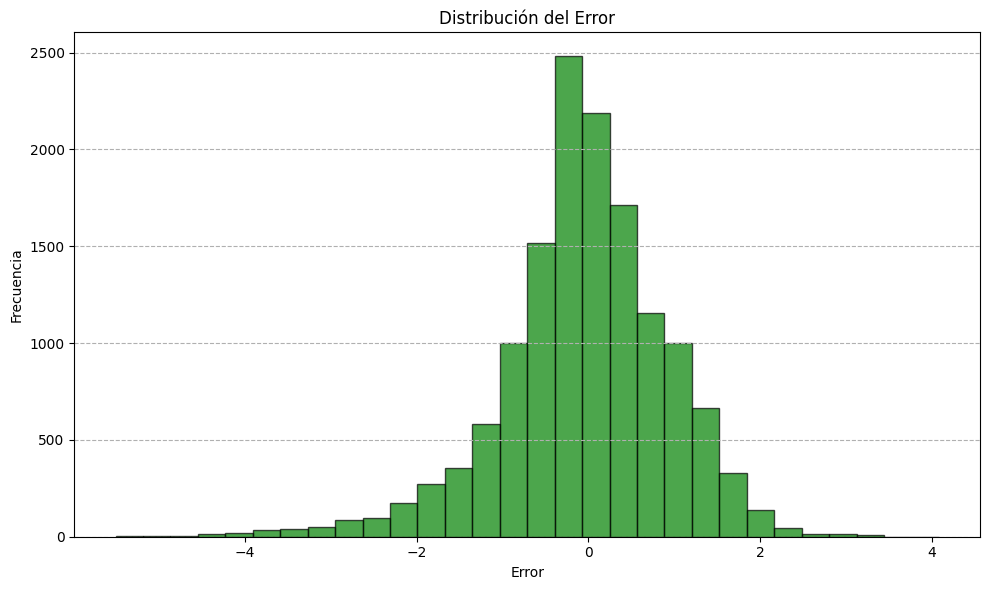

In [38]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))  # Establece el tamaño del gráfico
plt.hist(error.flatten(), bins=30, edgecolor='black', alpha=0.7, color = 'green')  # Añade bordes negros a las barras y ajusta la transparencia
plt.title('Distribución del Error')  # Añade un título al gráfico
plt.xlabel('Error')  # Etiqueta el eje x
plt.ylabel('Frecuencia')  # Etiqueta el eje y
plt.grid(axis='y', linestyle='--')  # Añade una cuadrícula horizontal
plt.tight_layout()  # Ajusta el diseño para evitar que se recorten las etiquetas
plt.show()

In [39]:
# Calcula el error absoluto para cada dato
absolute_error = np.abs(coefcampvectest - predictions)

# Calcula el error para cada dato
error = coefcampvectest - predictions

# Calcula la suma de los valores reales para cada dato
sum_real_values = np.sum(coefcampvectest, axis=-1)

# Divide el error absoluto por la suma de los valores reales para cada dato
relative_error_per_data = np.sum(absolute_error, axis=-1) / sum_real_values

# Calcula el MAE relativo como la media de los errores relativos
relative_mae = np.mean(relative_error_per_data)

# Divide el error por la suma de los valores reales para cada dato
relative_error_per_data_std_max = np.sum(error, axis=-1) / sum_real_values

# Calcula la desviación estándar del error relativo
relative_std_dev = np.std(relative_error_per_data_std_max)

# Calcula el error absoluto máximo relativo
relative_max_error = np.max(np.abs(relative_error_per_data_std_max))

print(f"MAE relativo: {relative_mae}")
print(f"Desviación estándar del error relativo: {relative_std_dev}")
print(f"Error absoluto máximo relativo: {relative_max_error}")

MAE relativo: 0.16257594934354724
Desviación estándar del error relativo: 0.1806330788688572
Error absoluto máximo relativo: 1.148445631328382


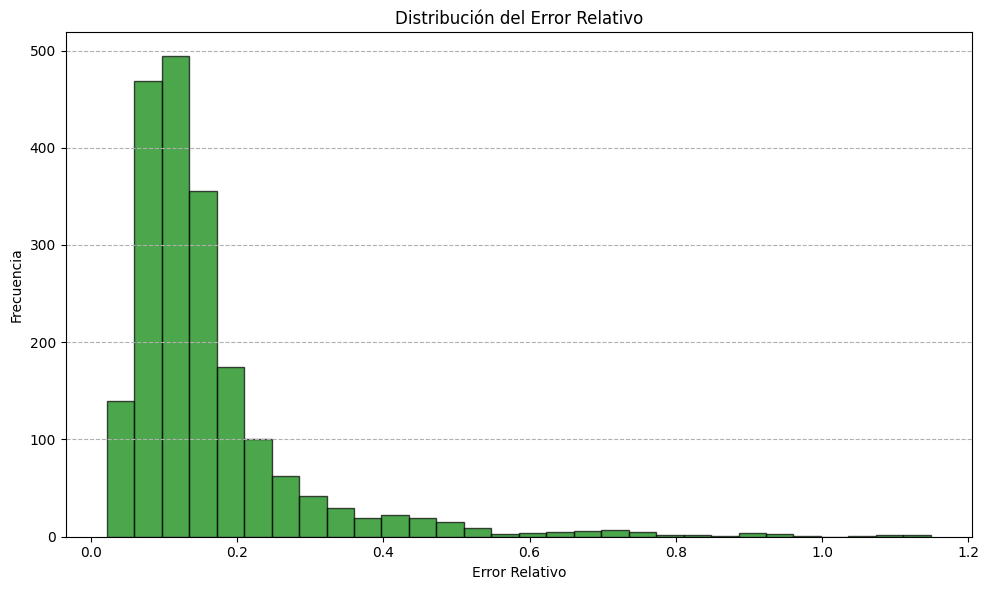

In [40]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))  # Establece el tamaño del gráfico
plt.hist(relative_error_per_data, bins=30, edgecolor='black', alpha=0.7, color = 'green')  # Añade bordes negros a las barras y ajusta la transparencia
plt.title('Distribución del Error Relativo')  # Añade un título al gráfico
plt.xlabel('Error Relativo')  # Etiqueta el eje x
plt.ylabel('Frecuencia')      # Etiqueta el eje y
plt.grid(axis='y', linestyle='--')  # Añade una cuadrícula horizontal
plt.tight_layout()  # Ajusta el diseño para evitar que se recorten las etiquetas
plt.show()

# Guardamos los datos de Accuracy y Loss

In [41]:
df = pd.DataFrame.from_dict(history.history)
df.to_csv('../../../Gráficas finales con ruido/grid100_traj200/historycampvec100.csv', index=False)

# Guardamos el modelo

In [42]:
path_to_save = '../../../trained_models_noisy/grid100_traj200'

In [43]:
model.save(path_to_save + '/campovectorial100.h5')

# Importamos el modelo

In [16]:
def custom_activation(x):
    return 10 * tf.nn.sigmoid(x)

In [17]:
coeficientesnombres = ('a_1', 'a_2', 'b_1', 'b_2', 'd_1', 'd_2', 'n')

def mse_component(i):
    def mse_i(y_true, y_pred):
        return tf.keras.losses.mean_absolute_error(y_true[:, i], y_pred[:, i])

    mse_i.__name__ = coeficientesnombres[i]
    return mse_i

def mean_metric(y_true, y_pred):
    total_loss = 0
    for i in range(7):
        total_loss += mse_component(i)(y_true, y_pred)
    sum_of_true_coefficients = tf.reduce_sum(y_true, axis=-1)
    return total_loss / sum_of_true_coefficients

metrics = [mse_component(i) for i in range(7)] + [mean_metric]

In [18]:
import keras
import tensorflow as tf
# Creación de un diccionario con todas las métricas personalizadas
custom_objects = {'custom_activation':custom_activation,'mean_metric': mean_metric}
for i in range(7):
    custom_objects[coeficientesnombres[i]] = mse_component(i)
new_model = keras.models.load_model('../../../trained_models_noisy/grid100_traj200/campovectorial100.h5', custom_objects=custom_objects)

# Probamos el modelo con datos nuevos

## Creamos nuevos datos

In [61]:
import random
from scipy.integrate import solve_ivp

campvec = []
contador = 0
for i in range(0, 1):
    # constantes
    a1 = random.randint(1, 10)
    a2 = random.randint(1, 10)
    b1 = random.randint(0, 10)
    b2 = random.randint(0, 10)
    d1 = random.randint(0, 10)
    d2 = random.randint(0, 10)
    n = random.randint(1, 5)

    coef1 = [a1, a2, b1, b2, d1, d2, n]

    def f(t, y):

        # asignar a cada ODE a un elemento de vector
        X = y[0]
        Y = y[1]

        # definimos cada ODE
        # dX_dt=a1/(1+Y**n)-d1*X+b1
        # dY_dt=a2/(1+X**n)-d2*Y+b2
        dX_dt = a1/(1+Y**n)-d1*X+b1
        dY_dt = a2/(1+X**n)-d2*Y+b1

        return [dX_dt, dY_dt]

    x_range_neg = 0
    x_range_pos = 10
    y_range_neg = 0
    y_range_pos =10

    y1 = np.linspace(x_range_neg, x_range_pos, 100)
    y2 = np.linspace(y_range_neg, y_range_pos, 100)

    Y1, Y2 = np.meshgrid(y1, y2)
    
    t1 = 0

    u, v = np.zeros(Y1.shape), np.zeros(Y2.shape)

    NI, NJ = Y1.shape

    u1, v1 = f(t1, [Y1, Y2])
    u, v = f(t1, [Y1, Y2])
    M = (np.hypot(u, v))
    u /= M
    v /= M

    campvecci = np.append([u1], [v1], axis=0)

    campvec = campvecci
    print('--------------------------------------------')
    print(coef1)

    
campvec = np.array(campvec)

--------------------------------------------
[7, 7, 5, 7, 8, 5, 3]


In [62]:
campvecnone = campvec[None, :]

## Predecimos con los datos nuevos

In [63]:
new_predictions = new_model.predict(campvecnone)
new_predictions = np.round(new_predictions)
new_predictions = np.clip(new_predictions, 0, None)
print(new_predictions)

1/1 [==============================] - 0s 12ms/step
[[7. 7. 5. 5. 8. 5. 3.]]


## Encontramos puntos de equilibrio datos reales

In [64]:
from scipy.optimize import fsolve
# Sistema de ecuaciones
def system(Y):
    X, Y = Y
    dX_dt = a1/(1+Y**n)-d1*X+b1
    dY_dt = a2/(1+X**n)-d2*Y+b1
    return [dX_dt, dY_dt]

# Adivinanza inicial para X, Y
initial_guess = [0, 0]

# Encontrar los puntos de equilibrio
primer_cuadrante_reales = fsolve(system, initial_guess)
primer_cuadrante_reales = tuple(primer_cuadrante_reales)


print(primer_cuadrante_reales)

(0.7196929521215416, 2.0198352992165316)


## Graficamos con los coeficientes reales

Text(0, 0.5, 'Concentración Y')

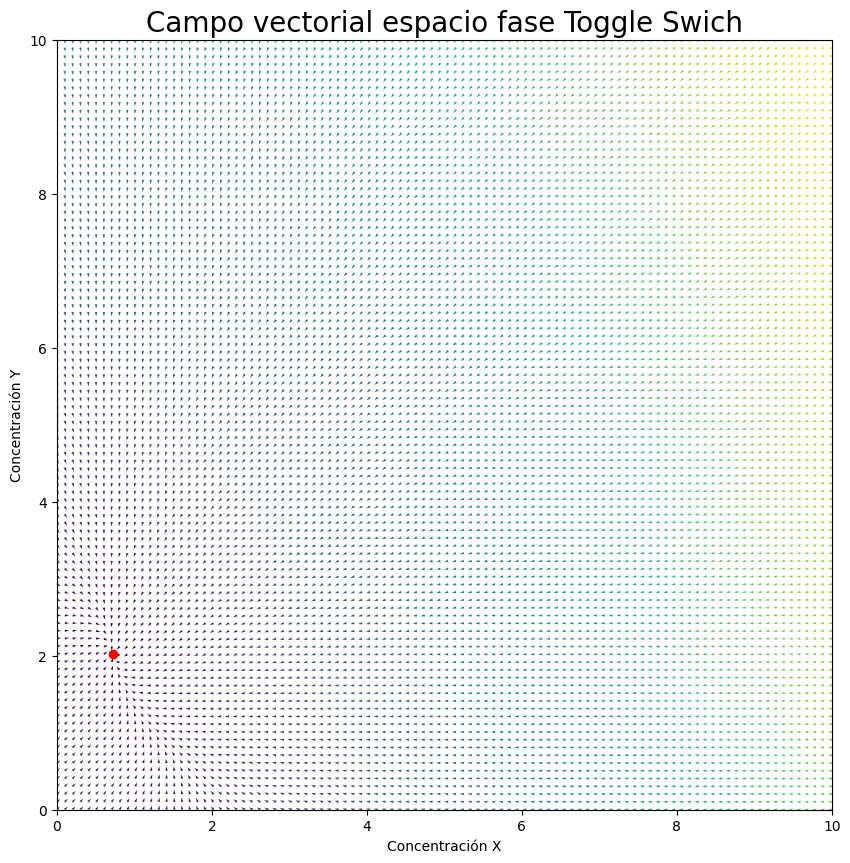

In [65]:
import matplotlib.pyplot as plt

x_values = primer_cuadrante_reales[0]
y_values =primer_cuadrante_reales[1]
y1 = np.linspace(0, 10, 100)
y2 = np.linspace(0, 10, 100)
Y1, Y2 = np.meshgrid(y1, y2)
t1 = 0
u, v = np.zeros(Y1.shape), np.zeros(Y2.shape)
NI, NJ = Y1.shape        
u,v = np.array(campvec)[0,:,:], np.array(campvec)[1,:,:]
M = (np.hypot(u,v))
u /= M
v /= M

plt.figure(figsize=(10,10))
Q = plt.quiver(Y1, Y2, u, v, M, angles='xy')
plt.title('Campo vectorial espacio fase Toggle Swich', fontsize=20)
plt.xlim([0, 10])
plt.ylim([0, 10])
plt.scatter(x_values, y_values, color='red')  # Puedes cambiar el color como prefieras
plt.xlabel('Concentración X')
plt.ylabel('Concentración Y')

## Encontramos puntos de equilibro datos predecidos

In [66]:
a1pred = new_predictions[0,0]
a2pred = new_predictions[0,1]
b1pred = new_predictions[0,2]
b2pred = new_predictions[0,3]
d1pred = new_predictions[0,4]
d2pred = new_predictions[0,5]
npred = new_predictions[0,6]

def systempred(Ypred):
    Xpred, Ypred = Ypred
    dXpred_dt = a1pred/(1+Ypred**npred)-d1pred*Xpred+b1pred
    dYpred_dt = a2pred/(1+Xpred**npred)-d2pred*Ypred+b1pred
    return [dXpred_dt, dYpred_dt]

# Adivinanza inicial para X, Y
initial_guesspred = [0, 0]

# Encontrar los puntos de equilibrio
primer_cuadrante_predecidos = fsolve(systempred, initial_guesspred)
primer_cuadrante_predecidos = tuple(primer_cuadrante_predecidos)


print(primer_cuadrante_predecidos)

(0.7196929521215416, 2.0198352992165316)


## Graficamos con los coeficientes predecidos

Text(0, 0.5, 'Concentración Y')

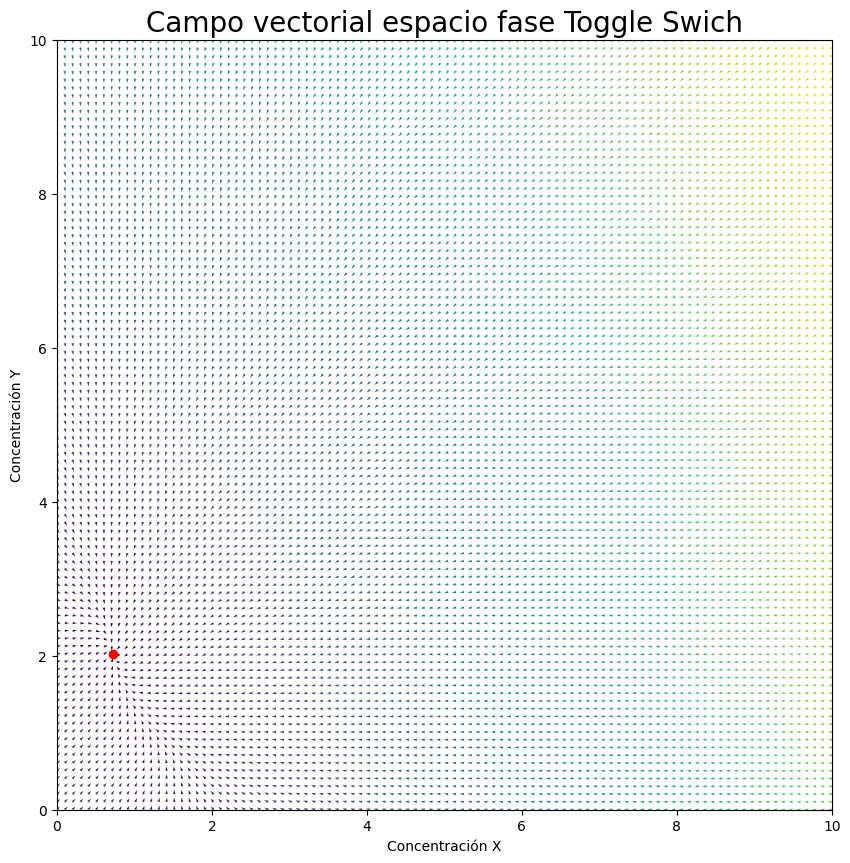

In [67]:
import matplotlib.pyplot as plt

def f(t, y):

    # asignar a cada ODE a un elemento de vector
    X = y[0]
    Y = y[1]

    # definimos cada ODE
    dX_dt = a1pred/(1+Y**npred)-d1pred*X+b1pred
    dY_dt = a2pred/(1+X**npred)-d2pred*Y+b1pred

    return [dX_dt, dY_dt]

x_range_neg = 0
x_range_pos = 10
y_range_neg = 0
y_range_pos = 10

y1pred = np.linspace(x_range_neg, x_range_pos, 100)
y2pred = np.linspace(y_range_neg, y_range_pos, 100)

Y1pred, Y2pred = np.meshgrid(y1pred, y2pred)
    
t1 = 0

upred, vpred = np.zeros(Y1pred.shape), np.zeros(Y2pred.shape)

NI, NJ = Y1.shape

u1pred, v1pred = f(t1, [Y1, Y2])
upred, vpred = f(t1, [Y1, Y2])
Mpred = (np.hypot(upred, vpred))
upred /= Mpred
vpred /= Mpred


x_valuespred = primer_cuadrante_predecidos[0]
y_valuespred =primer_cuadrante_predecidos[1]
plt.figure(figsize=(10, 10))
Q = plt.quiver(Y1, Y2, upred, vpred, Mpred, angles='xy')
plt.title('Campo vectorial espacio fase Toggle Swich', fontsize=20)
plt.xlim([x_range_neg, x_range_pos])
plt.ylim([y_range_neg, y_range_pos])
plt.scatter(x_valuespred, y_valuespred, color='red')  # Puedes cambiar el color como prefieras
plt.xlabel('Concentración X')
plt.ylabel('Concentración Y')

## Graficamos ambos

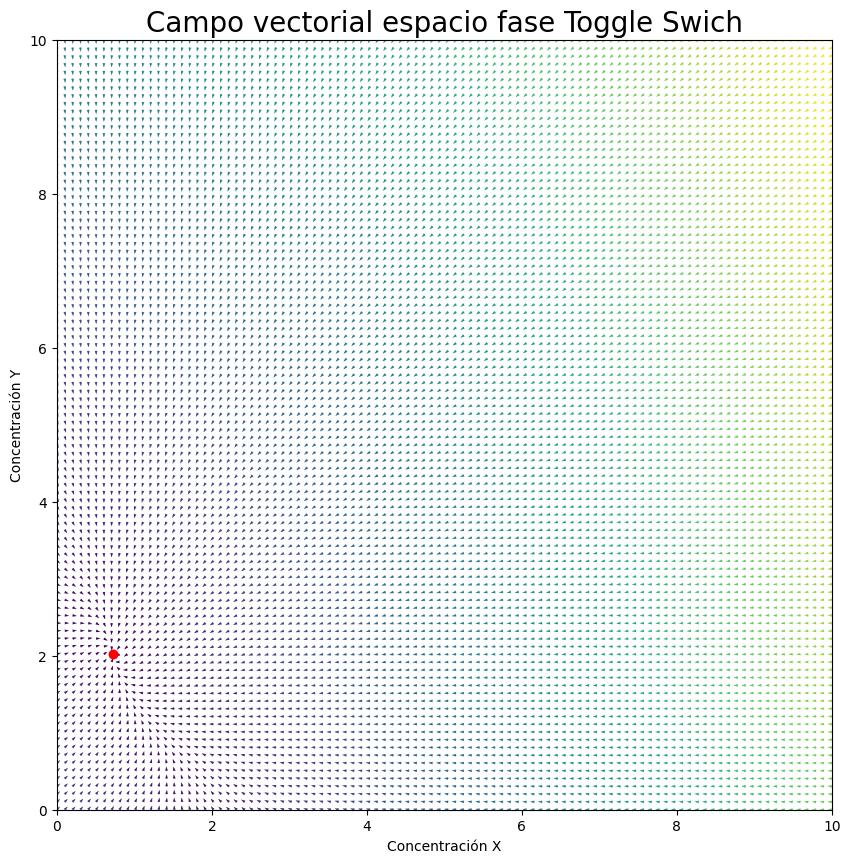

In [68]:
fig, ax = plt.subplots(figsize=(10, 10))

# Primero graficamos la predicción, que debería ser más clara (alpha < 1)
Q = ax.quiver(Y1, Y2, upred, vpred, Mpred, angles='xy', alpha=0.5)

# Luego, graficamos los datos originales, que serán más oscuros (alpha = 1)
Q1 = ax.quiver(Y1, Y2, u, v, M, angles='xy', alpha=1)

ax.scatter(x_valuespred, y_valuespred, color='red', alpha = 0.5)
ax.scatter(x_values, y_values, color='red', alpha = 1)
ax.set_title('Campo vectorial espacio fase Toggle Swich', fontsize=20)
ax.set_xlim([0, 10])
ax.set_ylim([0, 10])
ax.set_xlabel('Concentración X')
ax.set_ylabel('Concentración Y')

plt.show()

## Graficamos las diferencias

0.0


C:\Users\rafae\anaconda3\envs\tfcpu\lib\site-packages\matplotlib\quiver.py:646: RuntimeWarning: divide by zero encountered in double_scalars
  length = a * (widthu_per_lenu / (self.scale * self.width))
C:\Users\rafae\anaconda3\envs\tfcpu\lib\site-packages\matplotlib\quiver.py:646: RuntimeWarning: invalid value encountered in multiply
  length = a * (widthu_per_lenu / (self.scale * self.width))


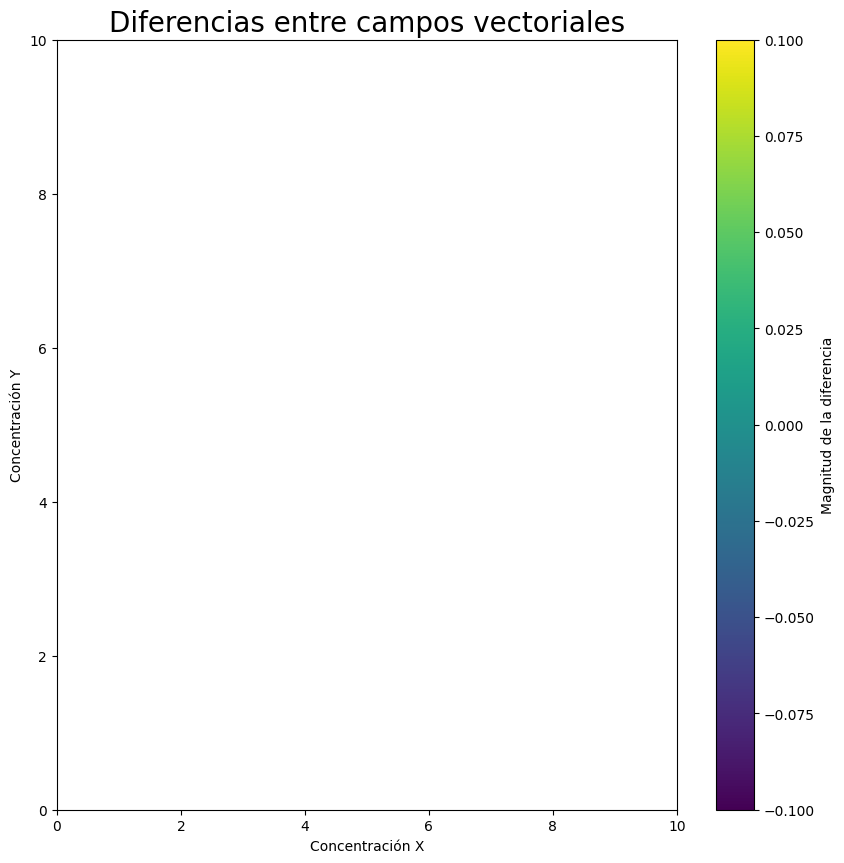

In [69]:
fig, ax = plt.subplots(figsize=(10, 10))

# Calculamos las diferencias
u_diff = u - upred
v_diff = v - vpred

# Ahora calculamos la magnitud
#M_diff = np.hypot(u_diff2, v_diff2)
M_diff = np.hypot(u_diff, v_diff)

#Calcula la magnitud de los vectores
magnitudes = np.sqrt(u_diff**2 + v_diff**2)

# Calcula el rango de las magnitudes
rango = (np.max(magnitudes) - np.min(magnitudes))*30
print(rango)
# Escala para las flechas. Aumenta este valor si las flechas son demasiado grandes.

# Graficamos las diferencias
#Q = ax.quiver(Y1, Y2, u_diff2, v_diff2, M_diff, angles='xy')
Q = ax.quiver(Y1, Y2, u_diff, v_diff, M_diff, angles='xy', scale = rango)
#Q = ax.quiver(Y1, Y2, u_diff, v_diff, M_diff, angles='xy')


ax.set_title('Diferencias entre campos vectoriales', fontsize=20)
ax.set_xlim([0, 10])
ax.set_ylim([0, 10])
ax.set_xlabel('Concentración X')
ax.set_ylabel('Concentración Y')

# Creamos una leyenda para la magnitud de las flechas
cbar = plt.colorbar(Q, ax=ax)
cbar.set_label('Magnitud de la diferencia')

plt.show()

## Errores relativos 

C:\Users\rafae\anaconda3\envs\tfcpu\lib\site-packages\matplotlib\quiver.py:646: RuntimeWarning: divide by zero encountered in double_scalars
  length = a * (widthu_per_lenu / (self.scale * self.width))
C:\Users\rafae\anaconda3\envs\tfcpu\lib\site-packages\matplotlib\quiver.py:646: RuntimeWarning: invalid value encountered in multiply
  length = a * (widthu_per_lenu / (self.scale * self.width))


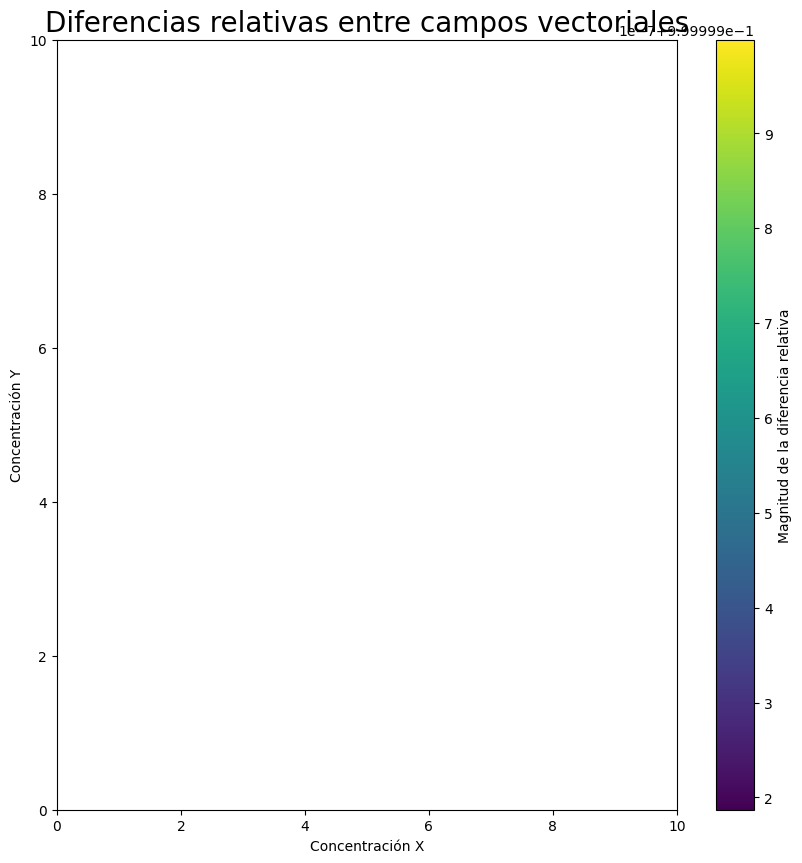

In [70]:
fig, ax = plt.subplots(figsize=(10, 10))

# Calculamos las diferencias
u_diff = u - upred
v_diff = v - vpred

# Aseguramos que ningún vector tenga una magnitud exactamente igual a cero
epsilon = 1e-7

# Calculamos la magnitud del vector original y de la diferencia
M_orig = np.hypot(u1, v1) + epsilon
M_diff = np.hypot(u1pred, v1pred)

# Calculamos la diferencia relativa
M_diff_rel = M_diff / M_orig

#Calcula la magnitud de los vectores
magnitudes = np.sqrt(u_diff**2 + v_diff**2)

# Calcula el rango de las magnitudes
rango = (np.max(magnitudes) - np.min(magnitudes))*30

# Graficamos las diferencias relativas
Q = ax.quiver(Y1, Y2, u_diff, v_diff, M_diff_rel, angles='xy', scale = rango)

ax.set_title('Diferencias relativas entre campos vectoriales', fontsize=20)
ax.set_xlim([0, 10])
ax.set_ylim([0, 10])
ax.set_xlabel('Concentración X')
ax.set_ylabel('Concentración Y')

# Creamos una leyenda para la magnitud de las flechas
cbar = plt.colorbar(Q, ax=ax)
cbar.set_label('Magnitud de la diferencia relativa')

plt.show()

In [71]:
max_index_flattened = M_diff_rel.argmax()
max_coords = np.unravel_index(max_index_flattened, M_diff_rel.shape)
M_orig[max_coords]
print('El valor máximo de error relativo es de:', M_diff_rel.max() )
print('El valor de u1 en el error relativo máximo es:',u1[max_coords])
print('El valor de u1pred en el error relativo máximo es:',u1pred[max_coords])
print('El valor de v1 en el error relativo máximo es:',v1[max_coords])
print('El valor de v1pred en el error relativo máximo es:',v1pred[max_coords])

El valor máximo de error relativo es de: 0.9999999988565508
El valor de u1 en el error relativo máximo es: -74.99300699300699
El valor de u1pred en el error relativo máximo es: -74.99300699300699
El valor de v1 en el error relativo máximo es: -44.99300699300699
El valor de v1pred en el error relativo máximo es: -44.99300699300699


In [72]:
# Calculamos las diferencias
u_diff = u - upred
v_diff = v - vpred

# Aseguramos que ningún vector tenga una magnitud exactamente igual a cero
epsilon = 1e-7

# Calculamos la magnitud del vector original y de la diferencia
M_orig = np.hypot(u, v) + epsilon
M_diff = np.hypot(u_diff, v_diff)

# Calculamos la diferencia relativa
M_diff_rel = M_diff / M_orig

# Aplicamos el filtro para la diferencia relativa mayor a 0.05
mask = M_diff_rel > 0.05

# Calculamos el porcentaje de puntos que cumplen con la condición
porcentaje = np.mean(mask) * 100

print(f"El porcentaje de puntos cuyo error relativo es mayor a 0.05 es {porcentaje:.2f}%")

El porcentaje de puntos cuyo error relativo es mayor a 0.05 es 0.00%


In [19]:
import numpy as np
import random
from scipy.optimize import fsolve

# Listas para almacenar los resultados
porcentajes = []

# Repetimos el proceso 10 veces
for repetir in range(1000):
    campvec = []
    coef = []
    # constantes
    a1 = random.randint(1, 10)
    a2 = random.randint(1, 10)
    b1 = random.randint(0, 10)
    b2 = random.randint(0, 10)
    d1 = random.randint(0, 10)
    d2 = random.randint(0, 10)
    n = random.randint(1, 5)

    coef1 = [a1, a2, b1, b2, d1, d2, n]
    coef.append(coef1)

    def ftrue(t, y):

        # asignar a cada ODE a un elemento de vector
        X = y[0]
        Y = y[1]

        # definimos cada ODE
        dX_dt = a1/(1+Y**n)-d1*X+b1
        dY_dt = a2/(1+X**n)-d2*Y+b2

        return [dX_dt, dY_dt]

    x_range_neg = 0
    x_range_pos = 10
    y_range_neg = 0
    y_range_pos = 10

    y1 = np.linspace(x_range_neg, x_range_pos, 100)
    y2 = np.linspace(y_range_neg, y_range_pos, 100)

    Y1, Y2 = np.meshgrid(y1, y2)
    
    t1 = 0

    u, v = np.zeros(Y1.shape), np.zeros(Y2.shape)

    NI, NJ = Y1.shape
    
    
    for i in range(NI):
        for j in range(NJ):
            # asignar a cada ODE a un elemento de vector
            X = Y1[i, j]
            Y = Y2[i, j]
            noise1 = np.random.normal(0, .5)
            noise2 = np.random.normal(0, .5)
            # definimos cada ODE
            dX_dt=(a1)/(1+Y**(n))-(d1)*X+b1+noise1
            dY_dt=(a2)/(1+X**(n))-(d2)*Y+b2+noise2
            u[i, j], v[i, j] = dX_dt, dY_dt

    M = (np.hypot(u, v))
    u /= M
    v /= M

    campvecci = np.append([u], [v], axis=0)

    campvec = campvecci
    print('--------------------------------------------')
    print(coef1)
    
    campvec = np.array(campvec)

    
    campvecnone = campvec[None, :]
    
    new_predictions = new_model.predict(campvecnone)
    new_predictions = np.round(new_predictions)
    new_predictions = np.clip(new_predictions, 0, None)
    print(new_predictions)
    
    
    a1pred = new_predictions[0,0]
    a2pred = new_predictions[0,1]
    b1pred = new_predictions[0,2]
    b2pred = new_predictions[0,3]
    d1pred = new_predictions[0,4]
    d2pred = new_predictions[0,5]
    npred = new_predictions[0,6]
    
    def f(t, y):

        # asignar a cada ODE a un elemento de vector
        X = y[0]
        Y = y[1]

        # definimos cada ODE
        dX_dt = a1pred/(1+Y**npred)-d1pred*X+b1pred
        dY_dt = a2pred/(1+X**npred)-d2pred*Y+b2pred

        return [dX_dt, dY_dt]

    x_range_neg = 0
    x_range_pos = 10
    y_range_neg = 0
    y_range_pos = 10

    y1pred = np.linspace(x_range_neg, x_range_pos, 100)
    y2pred = np.linspace(y_range_neg, y_range_pos, 100)

    Y1pred, Y2pred = np.meshgrid(y1pred, y2pred)
    
    t1 = 0

    upred, vpred = np.zeros(Y1pred.shape), np.zeros(Y2pred.shape)

    NI, NJ = Y1.shape

    upred, vpred = f(t1, [Y1, Y2])
    Mpred = (np.hypot(upred, vpred))
    upred /= Mpred
    vpred /= Mpred
    
    utrue, vtrue = np.zeros(Y1.shape), np.zeros(Y2.shape)

    NI, NJ = Y1.shape

    utrue, vtrue = ftrue(t1, [Y1, Y2])
    Mtrue = (np.hypot(utrue, vtrue))
    utrue /= Mtrue
    vtrue /= Mtrue  

 # Calculamos las diferencias
    u_diff = utrue - upred
    v_diff = vtrue - vpred

    # Aseguramos que ningún vector tenga una magnitud exactamente igual a cero
    epsilon = 1e-7

    # Calculamos la magnitud del vector original y de la diferencia
    M_orig = np.hypot(utrue, vtrue) + epsilon
    M_diff = np.hypot(u_diff, v_diff)

    # Calculamos la diferencia relativa
    M_diff_rel = M_diff / M_orig

    # Aplicamos el filtro para la diferencia relativa mayor a 0.05
    mask = M_diff_rel > 0.05

    # Calculamos el porcentaje de puntos que cumplen con la condición
    porcentaje = np.mean(mask) * 100

    # Almacenamos el resultado en la lista
    porcentajes.append(porcentaje)

    print(f"El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración {repetir+1} es {porcentaje:.2f}%")

# Muestra todos los porcentajes al final
print("Porcentajes para las 10 iteraciones:", porcentajes)

# Calcula y muestra el promedio de los porcentajes
promedio = np.mean(porcentajes)
print(f"El promedio de los porcentajes es {promedio:.2f}%")


--------------------------------------------
[9, 1, 4, 2, 8, 3, 2]
1/1 [==============================] - 0s 51ms/step
[[9. 1. 3. 1. 8. 3. 2.]]
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 1 es 11.91%
--------------------------------------------
[10, 10, 6, 4, 3, 6, 5]
1/1 [==============================] - 0s 10ms/step
[[9. 9. 6. 4. 3. 6. 4.]]
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 2 es 8.11%
--------------------------------------------
[10, 1, 3, 5, 6, 5, 2]
1/1 [==============================] - 0s 11ms/step
[[9. 1. 3. 5. 6. 5. 2.]]
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 3 es 2.77%
--------------------------------------------
[8, 8, 6, 1, 2, 6, 4]
1/1 [==============================] - 0s 12ms/step
[[7. 7. 5. 1. 2. 5. 4.]]
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 4 es 59.94%
--------------------------------------------
[10, 10, 3, 0, 10, 6, 3]
1

1/1 [==============================] - 0s 15ms/step
[[8. 3. 8. 4. 1. 7. 4.]]
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 36 es 20.39%
--------------------------------------------
[2, 8, 4, 3, 6, 9, 5]
1/1 [==============================] - 0s 12ms/step
[[2. 8. 5. 3. 7. 9. 4.]]
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 37 es 52.43%
--------------------------------------------
[1, 4, 0, 9, 1, 2, 5]
1/1 [==============================] - 0s 12ms/step
[[1. 5. 0. 8. 2. 2. 3.]]
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 38 es 91.62%
--------------------------------------------
[6, 9, 7, 1, 6, 8, 1]
1/1 [==============================] - 0s 12ms/step
[[7. 9. 7. 2. 6. 8. 1.]]
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 39 es 7.16%
--------------------------------------------
[6, 1, 6, 1, 10, 10, 2]
1/1 [==============================] - 0s 12ms/step
[[5. 1. 6. 1. 8

1/1 [==============================] - 0s 12ms/step
[[9. 8. 1. 8. 3. 4. 4.]]
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 71 es 33.29%
--------------------------------------------
[7, 3, 9, 9, 9, 2, 3]
1/1 [==============================] - 0s 13ms/step
[[6. 3. 8. 8. 8. 2. 3.]]
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 72 es 30.48%
--------------------------------------------
[9, 4, 8, 3, 6, 1, 2]
1/1 [==============================] - 0s 12ms/step
[[9. 4. 8. 3. 6. 1. 2.]]
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 73 es 0.00%
--------------------------------------------
[5, 1, 4, 3, 9, 0, 1]
1/1 [==============================] - 0s 11ms/step
[[4. 2. 5. 3. 9. 0. 2.]]
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 74 es 11.92%
--------------------------------------------
[7, 9, 7, 10, 2, 10, 1]
1/1 [==============================] - 0s 12ms/step
[[7. 8. 6. 8. 2

1/1 [==============================] - 0s 10ms/step
[[5. 1. 8. 7. 2. 9. 4.]]
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 106 es 22.19%
--------------------------------------------
[1, 9, 7, 7, 2, 1, 3]
1/1 [==============================] - 0s 11ms/step
[[2. 9. 7. 8. 2. 1. 3.]]
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 107 es 85.48%
--------------------------------------------
[7, 10, 0, 9, 10, 9, 4]
1/1 [==============================] - 0s 12ms/step
[[5. 7. 0. 7. 8. 7. 4.]]
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 108 es 2.46%
--------------------------------------------
[6, 8, 5, 5, 7, 10, 4]
1/1 [==============================] - 0s 11ms/step
[[6. 7. 5. 5. 7. 9. 4.]]
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 109 es 40.20%
--------------------------------------------
[9, 10, 6, 9, 8, 9, 2]
1/1 [==============================] - 0s 11ms/step
[[8. 8. 5

1/1 [==============================] - 0s 11ms/step
[[6. 9. 1. 4. 5. 8. 2.]]
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 141 es 6.81%
--------------------------------------------
[5, 5, 10, 0, 5, 8, 5]
1/1 [==============================] - 0s 12ms/step
[[5. 4. 9. 0. 5. 7. 4.]]
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 142 es 58.10%
--------------------------------------------
[7, 5, 9, 8, 1, 2, 4]
1/1 [==============================] - 0s 11ms/step
[[7. 4. 9. 8. 1. 2. 4.]]
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 143 es 8.47%
--------------------------------------------
[5, 8, 1, 0, 10, 2, 3]
1/1 [==============================] - 0s 12ms/step
[[5. 7. 1. 1. 9. 1. 4.]]
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 144 es 82.54%
--------------------------------------------
[4, 6, 5, 9, 6, 10, 4]
1/1 [==============================] - 0s 11ms/step
[[3. 6. 5. 

1/1 [==============================] - 0s 12ms/step
[[7. 8. 6. 8. 5. 9. 2.]]
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 176 es 3.76%
--------------------------------------------
[5, 4, 7, 3, 1, 0, 1]
1/1 [==============================] - 0s 12ms/step
[[8. 5. 8. 5. 1. 0. 1.]]
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 177 es 80.05%
--------------------------------------------
[9, 3, 2, 6, 6, 3, 4]
1/1 [==============================] - 0s 14ms/step
[[9. 2. 2. 7. 7. 3. 4.]]
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 178 es 62.81%
--------------------------------------------
[5, 2, 10, 7, 10, 1, 2]
1/1 [==============================] - 0s 12ms/step
[[5. 2. 9. 6. 9. 1. 2.]]
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 179 es 21.48%
--------------------------------------------
[8, 8, 10, 2, 6, 7, 4]
1/1 [==============================] - 0s 12ms/step
[[8. 7. 9.

... (19 outputs left out)

1/1 [==============================] - 0s 10ms/step
[[8. 8. 4. 4. 0. 9. 2.]]
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 876 es 15.36%
--------------------------------------------
[5, 5, 9, 8, 4, 4, 3]
1/1 [==============================] - 0s 11ms/step
[[5. 5. 9. 8. 4. 4. 3.]]
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 877 es 0.00%
--------------------------------------------
[7, 10, 8, 7, 4, 0, 4]
1/1 [==============================] - 0s 11ms/step
[[7. 8. 7. 7. 4. 0. 4.]]
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 878 es 34.17%
--------------------------------------------
[7, 5, 3, 10, 10, 3, 4]
1/1 [==============================] - 0s 10ms/step
[[6. 5. 3. 8. 9. 3. 4.]]
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 879 es 53.99%
--------------------------------------------
[3, 6, 4, 2, 4, 1, 5]
1/1 [==============================] - 0s 12ms/step
[[4. 9. 7.

1/1 [==============================] - 0s 11ms/step
[[9. 7. 5. 3. 1. 0. 5.]]
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 911 es 99.22%
--------------------------------------------
[4, 4, 8, 4, 2, 3, 5]
1/1 [==============================] - 0s 11ms/step
[[5. 4. 9. 5. 2. 3. 4.]]
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 912 es 59.30%
--------------------------------------------
[5, 5, 10, 6, 3, 9, 4]
1/1 [==============================] - 0s 10ms/step
[[5. 5. 9. 6. 3. 8. 4.]]
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 913 es 44.28%
--------------------------------------------
[7, 2, 9, 0, 4, 6, 5]
1/1 [==============================] - 0s 11ms/step
[[8. 2. 9. 0. 4. 7. 4.]]
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 914 es 46.73%
--------------------------------------------
[3, 6, 6, 8, 2, 10, 3]
1/1 [==============================] - 0s 11ms/step
[[2. 6. 6.

1/1 [==============================] - 0s 12ms/step
[[6. 9. 3. 5. 0. 2. 4.]]
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 946 es 85.53%
--------------------------------------------
[9, 1, 8, 1, 10, 10, 5]
1/1 [==============================] - 0s 10ms/step
[[8. 1. 7. 1. 8. 8. 4.]]
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 947 es 4.21%
--------------------------------------------
[7, 3, 8, 1, 0, 6, 2]
1/1 [==============================] - 0s 11ms/step
[[7. 2. 8. 1. 0. 6. 3.]]
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 948 es 3.30%
--------------------------------------------
[7, 10, 5, 3, 6, 2, 5]
1/1 [==============================] - 0s 11ms/step
[[7. 9. 6. 4. 6. 2. 4.]]
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 949 es 25.13%
--------------------------------------------
[5, 10, 5, 9, 5, 4, 4]
1/1 [==============================] - 0s 11ms/step
[[5. 9. 5.

1/1 [==============================] - 0s 10ms/step
[[3. 8. 8. 1. 2. 7. 1.]]
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 981 es 9.08%
--------------------------------------------
[7, 2, 2, 6, 3, 7, 1]
1/1 [==============================] - 0s 11ms/step
[[9. 3. 3. 7. 4. 9. 1.]]
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 982 es 6.47%
--------------------------------------------
[2, 3, 3, 6, 2, 5, 4]
1/1 [==============================] - 0s 11ms/step
[[2. 4. 5. 9. 3. 8. 4.]]
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 983 es 29.10%
--------------------------------------------
[4, 2, 1, 4, 0, 3, 4]
1/1 [==============================] - 0s 10ms/step
[[9. 4. 2. 8. 0. 6. 4.]]
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 984 es 0.00%
--------------------------------------------
[6, 10, 4, 9, 3, 1, 1]
1/1 [==============================] - 0s 10ms/step
[[5. 8. 5. 8. 